In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import matplotlib.patches as patches


fontsize = 7
plt.rcParams.update({
    'font.family': 'Arial',     # or 'Helvetica' if embedded properly
    'font.size': fontsize,
    'pdf.fonttype': 42,         # Embed TrueType (for editable text)
    'ps.fonttype': 42,
    'axes.labelsize': fontsize,
    'xtick.labelsize': fontsize,
    'ytick.labelsize': fontsize,
    'axes.facecolor': 'None',   # transparent background if needed
    'axes.edgecolor': 'black',
    'axes.linewidth': 0.5
})


blue = '#1E88E5'
red = '#FF1D25'

dir0 = "../"
dir1 = dir0+'data/'
dirf = dir0+'figures/'

In [ ]:

import pandas as pd
S = lambda m: pd.read_csv(dir1 + f"{m}/summary.csv").assign(label=lambda d: d["label"].fillna(""))

def theory(afs, asf, dr, D=1.0):        # returns (u or u_ms, u_mf)
    if afs > -dr and asf > dr:
        A = afs + asf
        ums = 2*np.sqrt(D*asf*(dr+afs)/A) if afs <= 0 else 2*np.sqrt(D*(dr+afs))
        return ums, 2*np.sqrt(D*(asf-dr))
    if asf > dr:
        return -2*np.sqrt(D*(asf-dr)), np.nan
    return 2*np.sqrt(D*max(dr, dr+afs)), np.nan

# 3A

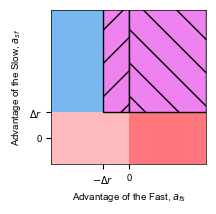

In [ ]:

aplot = 10 + np.arange(21)
fig, ax = plt.subplots( figsize=(2.,2.))
        
ax.set_xlabel('Advantage of the Fast, 'r'$a_{fs}$')
ax.set_ylabel('Advantage of the Slow, 'r'$a_{sf}$')

ax.set_yticks([0, 0.2]); ax.set_yticklabels([0, r'$\Delta r$'])
ax.set_xticks([-0.2, 0]); ax.set_xticklabels([r'$-\Delta r$', 0])

# Create a rectangle: (x, y), width, height
rect = patches.Rectangle((-0.6, 0.2), 0.4, 2.4, edgecolor='none', facecolor=blue, alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-0.6, -0.6), 0.6, 0.8, edgecolor='none', facecolor=red, alpha=0.3)
ax.add_patch(rect)
rect = patches.Rectangle((0.0, -0.6), 0.6, 0.8, edgecolor='none', facecolor=red, alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-0.2, 0.2), 0.2, 2.4, edgecolor='black', facecolor='violet', alpha=1, hatch='/')
ax.add_patch(rect)
rect = patches.Rectangle((-0., 0.2), 0.6, 2.4, edgecolor='black', facecolor='violet', alpha=1, hatch='\\')
ax.add_patch(rect)
ax.set_xlim(-0.6, 0.6)
ax.set_ylim(-0.2, 1.0)


fig.savefig(dirf + 'Fig3/3a_PD.pdf', bbox_inches='tight', transparent=True)

# 3B

In [ ]:
code = 'S1fraction'
date = "250501_L200_T300"
fname = "pd"

f = h5py.File(dir1 + code + '/'+ date + '/' + fname + '_hss.h5', "r"); hss = f["hss"][:]; f.close()
f = h5py.File(dir1 + code + '/'+ date + '/' + fname + '_fss.h5', "r"); fss = f["fss"][:]; f.close()
f = h5py.File(dir1 + code + '/'+ date + '/' + fname + '_ts.h5', "r"); ts = f["ts"][:]; f.close()

nbin_a = 41;#hss.shape[0]
a12s = np.linspace(-2, 2, nbin_a)
a21s = np.linspace(-2, 2, nbin_a)
r1 = 1.0
r2 = 0.8

hss = hss.swapaxes(3,0); hss = hss.swapaxes(2,1)
fss = fss.swapaxes(3,0); fss = fss.swapaxes(2,1)


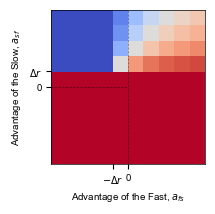

In [ ]:
fig, ax = plt.subplots(figsize=(2,2))

img = np.copy( fss[:,:,100,-1].T )
img2 = img[np.arange(20)*2+1]
img2 = img2[:,np.arange(20)*2+1]

ax.set_ylim(-0.5+5, 19.5-5)
ax.set_xlim(-0.5+5, 19.5-5)
a = ax.imshow(  img2, vmin=0, vmax=1, cmap=plt.cm.coolwarm)
ax.set_xticks([8.5, 9.5]); ax.set_xticklabels([r'$-\Delta r$',0])
ax.set_yticks([9.5, 10.5]); ax.set_yticklabels([0, r'$\Delta r$'])
ax.plot(np.linspace(0,9.5,10),np.zeros(10)+9.5,'k--',linewidth=0.5, alpha=0.5)
ax.plot(np.zeros(10)+9.5,np.linspace(0,19,10),'k--',linewidth=0.5, alpha=0.5)
        
ax.set_xlabel('Advantage of the Fast, 'r'$a_{fs}$')
ax.set_ylabel('Advantage of the Slow, 'r'$a_{sf}$')
fig.savefig(dirf + 'Fig3/3b_PD.pdf', bbox_inches='tight', transparent=True)

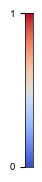

In [ ]:
## colorbar
fig, ax = plt.subplots(figsize=(0.1, 2));
gradient = np.linspace(1, 0, 257)
gradient = np.vstack((gradient, gradient)).T
ax.imshow(gradient, aspect='auto', cmap='coolwarm')
ax.set_xticks([]); ax.set_yticks([0, 256]); ax.set_yticklabels([1, 0])
#ax.set_ylabel('Asymptotic fraction of Fast type'); 
fig.savefig(dirf + 'Fig3/3b_cbar.pdf', bbox_inches='tight', transparent=True)

# 3C

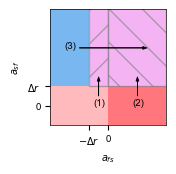

In [ ]:

aplot = 10 + np.arange(21)
fig, ax = plt.subplots( figsize=(1.5,1.5))
        
ax.set_xlabel(r'$a_{fs}$')
ax.set_ylabel(r'$a_{sf}$')
#ax.plot( np.linspace(-1, 1, 10), np.zeros(10)+0.2, 'k', alpha=0.5, linewidth=0.5 )
#ax.plot( np.zeros(10)-0.2, np.linspace(0.2, 1, 10),  'k', alpha=0.5, linewidth=0.5 )
#ax.plot( np.zeros(10), np.linspace(-1, 0.2, 10),  'k', alpha=0.5, linewidth=0.5 )
#ax.plot( np.zeros(10), np.linspace(-1, 1, 10),  'k', alpha=0.5, linewidth=0.5, linestyle='--' )
#ax.plot( np.linspace(-1, 1, 10), np.zeros(10),  'k', alpha=0.5, linewidth=0.5, linestyle='--' )

ax.set_yticks([0, 0.2]); ax.set_yticklabels([0, r'$\Delta r$'])
ax.set_xticks([-0.2, 0]); ax.set_xticklabels([r'$-\Delta r$', 0])

# Create a rectangle: (x, y), width, height
rect = patches.Rectangle((-0.6, 0.2), 0.4, 2.4, edgecolor='none', facecolor=blue, alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-0.6, -0.6), 0.6, 0.8, edgecolor='none', facecolor=red, alpha=0.3)
ax.add_patch(rect)
rect = patches.Rectangle((0.0, -0.6), 0.6, 0.8, edgecolor='none', facecolor=red, alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-0.2, 0.2), 0.2, 2.4, edgecolor='grey', facecolor='violet', alpha=0.6, hatch='/')
ax.add_patch(rect)
rect = patches.Rectangle((-0., 0.2), 0.6, 2.4, edgecolor='grey', facecolor='violet', alpha=0.6, hatch='\\')
ax.add_patch(rect)
#ax.text(-0.55, 0.4, 'slow invades fast')
#ax.text(-0.5, -0.2, 'fast grower\ninvades')
ax.set_xlim(-0.6, 0.6)
ax.set_ylim(-0.2, 1.0)

ax.arrow( -0.1, 0.1, 0, 0.2, length_includes_head=True, head_width=0.03, linewidth=0.5, shape='full', facecolor='black')
ax.arrow( 0.3, 0.1, 0, 0.2, length_includes_head=True, head_width=0.03, linewidth=0.5, shape='full', facecolor='black')
ax.arrow( -0.3, 0.6, 0.7, 0., length_includes_head=True, head_width=0.03, linewidth=0.5, shape='full', facecolor='black')

ax.text(-0.15, 0., '(1)')
ax.text(0.25, 0., '(2)')
ax.text(-0.45, 0.6, '(3)')


fig.savefig(dirf + 'Fig3/3c_PD.pdf', bbox_inches='tight', transparent=True)

In [35]:
def fig3_theory(afs, asf, dr, D=1.0):
    """u_fs: fast into slow; u_sf: slow into fast (dent, >0); u_ms / u_mf: mixture into slow / fast."""
    afs, asf = np.broadcast_arrays(np.asarray(afs, float), np.asarray(asf, float))
    coex = (afs > -dr) & (asf > dr)
    dent = (asf > dr) & (afs <= -dr)
    fast = asf <= dr
    with np.errstate(invalid="ignore", divide="ignore"):
        geo_mix     = 2*np.sqrt(D*asf*(dr + afs)/(afs + asf))   # circular bulge of the mixture
        fisher_fast = 2*np.sqrt(D*(dr + afs))                   # rare fast advantage s(0)
        fisher_slow = 2*np.sqrt(D*(asf - dr))                   # rare slow advantage -s(1)
        out = dict(
            u_fs=np.where(fast, 2*np.sqrt(D*np.maximum(dr, dr + afs)), np.nan),
            u_sf=np.where(dent, fisher_slow, np.nan),
            u_ms=np.where(coex, np.where(afs <= 0, geo_mix, fisher_fast), np.nan),
            u_mf=np.where(coex, fisher_slow, np.nan),
        )
    return out

In [85]:
f3 = S("fig3")
t = f3[f3.label == "traj1"].sort_values("asf")    # traj2 the same way; traj3: sort and plot by "afs"
cx = t.regime == "coex"
u_fs = t.u_late[~cx]                 # pure fast into slow (black, before coexistence)
u_ms = t.u_late[cx]                  # mixture into slow (blue)
u_mf = t.u2_late[cx]                 # mixture into fast (red)
# traj3: u_sf = -t.u_late[t.regime == "dent"]   (the dent velocity is negative in our sign convention)

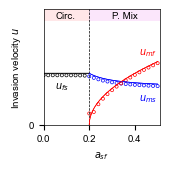

In [ ]:
fig, ax = plt.subplots(figsize=(1.5,1.5))

rect = patches.Rectangle((0.2, 1.8), 0.35, 2, edgecolor='none', facecolor='violet', alpha=0.2)
ax.add_patch(rect)
rect = patches.Rectangle((-0.55, 1.8), 0.75, 2, edgecolor='none', facecolor=red, alpha=0.1)
ax.add_patch(rect)

ax.text(0.05, 1.85,'Circ.')
ax.text(0.3, 1.85,'P. Mix')
ax.set_yticks([0])
ax.axvline(0.2, color='k', ls='--', lw=0.5)
ax.scatter(t.asf[~cx], u_fs, s=5, color='none', edgecolor='k', marker='o', linewidth=0.5)
ax.scatter(t.asf[cx], u_ms, s=5, color='none', edgecolor='b', marker='o', linewidth=0.5)
ax.scatter(t.asf[cx], u_mf, s=5, color='none', edgecolor='r', marker='o', linewidth=0.5)

ax.set_ylim(0, 2.0)

f3 = S("fig3"); dr = (f3.rf - f3.rs).iloc[0]; D = f3.D.iloc[0]
s = np.linspace(0, 0.5, 2001)                  # traj1 and traj2: a_sf varies
f = np.linspace(-0.5, 0.5, 2001)               # traj3: a_fs varies
T1 = fig3_theory(-0.1, s, dr, D)               # circular bulge -> parasitic mixture
T2 = fig3_theory( 0.2, s, dr, D)               # composite bulge -> mutualistic mixture
T3 = fig3_theory(f, 0.4, dr, D)                # dent -> parasitic -> mutualistic

for x, T in zip((s, s), (T1, T1)):
    ax.plot(x, T["u_fs"], "k-", lw=0.5); ax.plot(x, T["u_sf"], "k-", lw=0.5)
    ax.plot(x, T["u_ms"], "b-", lw=0.5); ax.plot(x, T["u_mf"], "r-", lw=0.5)


ax.set_xlabel(r'$a_{sf}$')
ax.set_ylabel(r'Invasion velocity $u$')
ax.text(0.05,0.62,r'$u_{fs}$')
ax.text(0.42,1.22,r'$u_{mf}$',color='r')
ax.text(0.42,0.42,r'$u_{ms}$',color='b')
ax.set_xlim(0, 0.51)
fig.savefig(dirf + 'Fig3/3c_plot1.pdf', bbox_inches='tight', transparent=True)

In [68]:
f3 = S("fig3")
t = f3[f3.label == "traj2"].sort_values("asf")    # traj2 the same way; traj3: sort and plot by "afs"
cx = t.regime == "coex"
u_fs = t.u_late[~cx]                 # pure fast into slow (black, before coexistence)
u_ms = t.u_late[cx]                  # mixture into slow (blue)
u_mf = t.u2_late[cx]                 # mixture into fast (red)
# traj3: u_sf = -t.u_late[t.regime == "dent"]   (the dent velocity is negative in our sign convention)

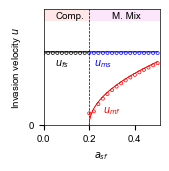

In [ ]:
fig, ax = plt.subplots(figsize=(1.5,1.5))

rect = patches.Rectangle((0.2, 1.8), 0.35, 2, edgecolor='none', facecolor='violet', alpha=0.2)
ax.add_patch(rect)
rect = patches.Rectangle((-0.55, 1.8), 0.75, 2, edgecolor='none', facecolor=red, alpha=0.1)
ax.add_patch(rect)

ax.text(0.05, 1.85,'Comp.')
ax.text(0.3, 1.85,'M. Mix')
ax.set_yticks([0])
ax.axvline(0.2, color='k', ls='--', lw=0.5)
ax.scatter(t.asf[~cx], u_fs, s=5, color='none', edgecolor='k', marker='o', linewidth=0.5)
ax.scatter(t.asf[cx], u_ms, s=5, color='none', edgecolor='b', marker='o', linewidth=0.5)
ax.scatter(t.asf[cx], u_mf, s=5, color='none', edgecolor='r', marker='o', linewidth=0.5)

ax.set_ylim(0, 2.0)

for x, T in zip((s, s), (T2, T2)):
    ax.plot(x, T["u_fs"], "k-", lw=0.5); ax.plot(x, T["u_sf"], "k-", lw=0.5)
    ax.plot(x, T["u_ms"], "b-", lw=0.5); ax.plot(x, T["u_mf"], "r-", lw=0.5)


ax.set_xlabel(r'$a_{sf}$')
ax.set_ylabel(r'Invasion velocity $u$')
ax.text(0.05,1.02,r'$u_{fs}$')
ax.text(0.26,0.22,r'$u_{mf}$',color='r')
ax.text(0.22,1.02,r'$u_{ms}$',color='b')
ax.set_xlim(0, 0.51)
fig.savefig(dirf + 'Fig3/3c_plot2.pdf', bbox_inches='tight', transparent=True)

In [74]:
f3 = S("fig3")
t = f3[f3.label == "traj3"].sort_values("asf")    # traj2 the same way; traj3: sort and plot by "afs"
cx = t.regime == "coex"
u_fs = t.u_late[~cx]                 # pure fast into slow (black, before coexistence)
u_ms = t.u_late[cx]                  # mixture into slow (blue)
u_mf = t.u2_late[cx]                 # mixture into fast (red)
u_sf = -t.u_late[t.regime == "dent"] # (the dent velocity is negative in our sign convention)

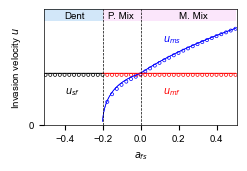

In [ ]:
fig, ax = plt.subplots(figsize=(2.5,1.5))

rect = patches.Rectangle((-0.55, 1.8), 0.35, 2, edgecolor='none', facecolor=blue, alpha=0.2)
ax.add_patch(rect)
rect = patches.Rectangle((-0.2, 1.8), 0.7, 2, edgecolor='none', facecolor='violet', alpha=0.2)
ax.add_patch(rect)

ax.text(-0.4, 1.85,'Dent')
ax.text(-0.17, 1.85,'P. Mix')
ax.text(0.2, 1.85,'M. Mix')
ax.set_yticks([0])


ax.set_ylim(0, 2.0)
ax.scatter(t.afs[~cx], u_fs, s=5, color='none', edgecolor='k', marker='o', linewidth=0.5)
ax.scatter(t.afs[~cx], u_sf, s=5, color='none', edgecolor='k', marker='o', linewidth=0.5)
ax.scatter(t.afs[cx], u_ms, s=5, color='none', edgecolor='b', marker='o', linewidth=0.5)
ax.scatter(t.afs[cx], u_mf, s=5, color='none', edgecolor='r', marker='o', linewidth=0.5)

for x, T in zip((f, f), (T3, T3)):
    ax.plot(x, T["u_fs"], "k-", lw=0.5); ax.plot(x, T["u_sf"], "k-", lw=0.5)
    ax.plot(x, T["u_ms"], "b-", lw=0.5); ax.plot(x, T["u_mf"], "r-", lw=0.5)


ax.set_xlabel(r'$a_{fs}$')
ax.set_ylabel(r'Invasion velocity $u$')
ax.text(-0.4,0.55,r'$u_{sf}$')
ax.text(0.12,0.55,r'$u_{mf}$',color='r')
ax.text(0.12,1.45,r'$u_{ms}$',color='b')
ax.set_xlim(-0.51, 0.51)
#ax.set_ylim(0, 0.75)
ax.axvline(-0.2, color='k', ls='--', lw=0.5)
ax.axvline(0., color='k', ls='--', lw=0.5)
fig.savefig(dirf + 'Fig3/3c_plot3.pdf', bbox_inches='tight', transparent=True)